In [7]:
import os, shutil, random, hashlib
from collections import defaultdict

# ================== CẤU HÌNH ==================
BASE = r"C:\Users\LENOVO\do_an\dataset"

IMG_SRC = os.path.join(BASE, "original", "pin")        # ảnh gốc
LBL_SRC = os.path.join(BASE, "label", "pin")     # label gốc

# Nơi lưu sau khi chia (thư mục ảnh train/val/test mình tự đặt tên, bạn sửa nếu muốn)
DEST = {
    "train": {"img": os.path.join(BASE, "repair_dataset","pin", "train", "images"),
              "lbl": os.path.join(BASE, "repair_dataset","pin", "train", "labels")},
    "val":   {"img": os.path.join(BASE, "repair_dataset","pin", "val", "images"),
              "lbl": os.path.join(BASE, "repair_dataset","pin", "val", "labels")},
    "test":  {"img": os.path.join(BASE, "repair_dataset","pin", "test", "images"),
             "lbl": os.path.join(BASE, "repair_dataset","pin", "test", "labels")},
}
RATIOS = {"train": 0.7, "val": 0.2, "test": 0.1}
SEED = 42            # đổi số này sẽ ra cách chia khác; giữ nguyên để chia lại y hệt
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
# ==============================================

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

# 1) Chặn ghi đè / trộn lẫn vào thư mục đã có dữ liệu
for s, d in DEST.items():
    for p in d.values():
        if os.path.isdir(p) and os.listdir(p):
            raise RuntimeError(f"Thư mục đích không rỗng: {p}\nHãy xoá/đổi tên rồi chạy lại.")

# 2) Ghép ảnh với label (cùng tên, đuôi .txt)
imgs = sorted(f for f in os.listdir(IMG_SRC) if f.lower().endswith(IMG_EXT))
pairs, no_label = [], []
for f in imgs:
    lbl = os.path.splitext(f)[0] + ".txt"
    (pairs if os.path.exists(os.path.join(LBL_SRC, lbl)) else no_label).append((f, lbl))
no_label = [f for f, _ in no_label]

# 3) Gom các ảnh có nội dung GIỐNG HỆT nhau vào cùng nhóm
#    -> nhóm này luôn nằm chung 1 tập, nên không thể bị trùng giữa các tập
groups = defaultdict(list)
for f, l in pairs:
    groups[md5(os.path.join(IMG_SRC, f))].append((f, l))
groups = list(groups.values())
random.Random(SEED).shuffle(groups)

# 4) Chia theo tỉ lệ (đếm theo số ảnh)
N = len(pairs)
n_train = round(N * RATIOS["train"])
n_val_end = n_train + round(N * RATIOS["val"])
split = {"train": [], "val": [], "test": []}
count = 0
for g in groups:
    name = "train" if count < n_train else "val" if count < n_val_end else "test"
    split[name].extend(g)
    count += len(g)

# 5) Kiểm tra không tập nào chứa ảnh của tập khác
stems = {s: {os.path.splitext(f)[0] for f, _ in v} for s, v in split.items()}
assert not (stems["train"] & stems["val"]), "train/val trùng"
assert not (stems["train"] & stems["test"]), "train/test trùng"
assert not (stems["val"] & stems["test"]), "val/test trùng"

# 6) Copy (giữ nguyên file gốc, không di chuyển)
for s, items in split.items():
    os.makedirs(DEST[s]["img"], exist_ok=True)
    os.makedirs(DEST[s]["lbl"], exist_ok=True)
    for f, l in items:
        shutil.copy2(os.path.join(IMG_SRC, f), os.path.join(DEST[s]["img"], f))
        shutil.copy2(os.path.join(LBL_SRC, l), os.path.join(DEST[s]["lbl"], l))

# 7) Báo cáo
print(f"Tổng ảnh có label: {N}")
for s in ("train", "val", "test"):
    print(f"  {s:<5}: {len(split[s]):>5} ảnh  ({len(split[s]) / max(N, 1):.1%})")
dup_groups = [g for g in groups if len(g) > 1]
if dup_groups:
    print(f"\nCó {len(dup_groups)} nhóm ảnh giống hệt nhau (đã xếp chung 1 tập):")
    for g in dup_groups[:10]:
        print("  ", [f for f, _ in g])
if no_label:
    print(f"\n⚠ {len(no_label)} ảnh KHÔNG có label nên bị bỏ qua: {no_label[:10]}"
          + (" ..." if len(no_label) > 10 else ""))
print("\nXong. Đã kiểm tra: 3 tập không có ảnh nào trùng nhau.")

Tổng ảnh có label: 156
  train:   109 ảnh  (69.9%)
  val  :    31 ảnh  (19.9%)
  test :    16 ảnh  (10.3%)

Có 4 nhóm ảnh giống hệt nhau (đã xếp chung 1 tập):
   ['baterry141.jpg', 'baterry92.jpg']
   ['baterry140.jpg', 'baterry88.jpg']
   ['baterry139.jpg', 'baterry87.jpg']
   ['baterry142.jpg', 'baterry94.jpg']

⚠ 1 ảnh KHÔNG có label nên bị bỏ qua: ['baterry35.jpg']

Xong. Đã kiểm tra: 3 tập không có ảnh nào trùng nhau.


In [4]:
# copy_trung_ten.py
# Tim cac anh co ten TRUNG o 2 folder (mau va xam), roi copy CA HAI ban sang 1 folder moi.
# Them hau to vao ten file de 2 ban khong ghi de len nhau.
# Chay:  python copy_trung_ten.py

import shutil
from pathlib import Path

SRC_DIR = r"C:\Users\LENOVO\do_an\dataset_gray\train_and_validation\train\images"     # folder anh mau
REF_DIR = r"C:\Users\LENOVO\do_an\dataset_gray\grayscaled_label\total_label"    # folder anh trang den
OUT_DIR = r"C:\Users\LENOVO\do_an\dataset_gray\train_and_validation\test"         # folder moi de chua cac anh trung ten

def main():
    src, ref, out = Path(SRC_DIR), Path(REF_DIR), Path(OUT_DIR)
    out.mkdir(parents=True, exist_ok=True)
 
    for p in src.iterdir():
        if p.is_file() and (ref / p.name).is_file():
            shutil.copy2(p, out / p.name)
            print(p.name)
 
 
if __name__ == "__main__":
    main()

baterry101.jpg
baterry102.jpg
baterry111.jpg
baterry123.jpg
baterry137.jpg
baterry152.jpg
baterry156.jpg
baterry16.jpg
baterry45.jpg
baterry51.jpg
baterry67.jpg
baterry7.png
baterry71.jpg
baterry74.jpg
baterry79.jpg
baterry83.jpg
baterry98.jpg
Electrical_outlet14.jpg
Electrical_outlet31.jpg
Electrical_outlet33.jpg
Electrical_outlet36.jpg
Electrical_outlet38.jpg
Electrical_outlet49.jpg
Electrical_outlet50.jpg
Electrical_outlet73.jpg
Electrical_outlet81.jpg
Electrical_outlet82.jpg
Electrical_outlet9.jpg
Electrical_outlet94.jpg
Electrical_outlet95.jpg
Electrical_outlet99.jpg
knife115.jpg
knife125.jpg
knife128.jpg
knife139.jpg
knife142.jpg
knife182.jpg
knife186.jpg
knife19.jpg
knife202.jpg
knife205.jpg
knife208.jpg
knife213.jpg
knife220.jpg
knife222.jpg
knife26.jpg
knife262.jpg
knife41.jpg
knife46.jpg
knife51.jpg
knife94.jpg
scissor33.jpg
scissor41.jpg
scissor56.jpg
scissor57.jpg
scissor62.jpg
scissor67.jpg
scissor75.jpg
scissor8.jpg
scissor81.jpg
scissor82.jpg


In [2]:
from pathlib import Path
from collections import Counter
import shutil

root = Path(r"C:\Users\LENOVO\do_an\dataset\train_and_validation")

# Tiền tố tên file (viết thường) -> class_id. Khớp với thứ tự names trong data.yaml
mapping = {
    "baterry": 0,
    "electrical_outlet": 1,
    "knife": 2,
    "scissor": 3,
    "baby": 4,          # <-- đổi thành tiền tố tên file ảnh trẻ em của bạn
}

DRY_RUN = True   # True: chỉ in ra, không ghi. Kiểm tra xong đổi thành False

# 1) Sao lưu nhãn (chỉ làm một lần, khi thật sự ghi)
if not DRY_RUN:
    for split in ["train", "val"]:
        bak = root / split / "labels_backup"
        if not bak.exists():
            shutil.copytree(root / split / "labels", bak)

# 2) Ánh xạ lại class_id
unknown, multi_box = [], []
for split in ["train", "val"]:
    for f in (root / split / "labels").glob("*.txt"):
        name = f.stem.lower()
        cid = next((v for k, v in mapping.items() if name.startswith(k)), None)
        if cid is None:
            unknown.append(f.name)
            continue
        rows = [l.split() for l in f.read_text().splitlines() if l.strip()]
        if len(rows) > 1:
            multi_box.append(f.name)     # có nhiều hộp: có thể chứa nhiều lớp khác nhau
        if not DRY_RUN:
            new = [f"{cid} " + " ".join(r[1:]) for r in rows]
            f.write_text("\n".join(new) + "\n")

print("Không nhận ra tên:", len(unknown), unknown[:10])
print("File có nhiều hộp (nên kiểm tra tay):", len(multi_box), multi_box[:10])

# 3) Xóa cache nhãn
if not DRY_RUN:
    for split in ["train", "val"]:
        c = root / split / "labels.cache"
        if c.exists():
            c.unlink()

# 4) Thống kê số đối tượng theo class
for split in ["train", "val"]:
    cnt = Counter()
    for f in (root / split / "labels").glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                cnt[line.split()[0]] += 1
    print(split, dict(sorted(cnt.items())))

Không nhận ra tên: 0 []
File có nhiều hộp (nên kiểm tra tay): 184 ['baby1.txt', 'baby100.txt', 'baby12.txt', 'baby13.txt', 'baby14.txt', 'baby16.txt', 'baby17.txt', 'baby19.txt', 'baby20.txt', 'baby23.txt']
train {'0': 316, '1': 77, '2': 271, '3': 81}
val {'0': 78, '1': 23, '2': 88, '3': 25}


In [3]:
from pathlib import Path
from collections import Counter, defaultdict
import re

root = Path(r"C:\Users\LENOVO\do_an\dataset\train_and_validation")

for split in ["train", "val"]:
    files = list((root/split/"labels").glob("baby*.txt"))
    per_class = Counter()
    boxes_per_file = []
    for f in files:
        rows = [l.split() for l in f.read_text().splitlines() if l.strip()]
        boxes_per_file.append(len(rows))
        for r in rows:
            per_class[r[0]] += 1
    print(f"[{split}] số file baby: {len(files)}, tổng hộp: {sum(boxes_per_file)}")
    print("  class trong file baby:", dict(sorted(per_class.items())))
    if boxes_per_file:
        print("  hộp/file: nhỏ nhất", min(boxes_per_file),
              "lớn nhất", max(boxes_per_file),
              "trung bình", round(sum(boxes_per_file)/len(boxes_per_file), 1))

# In nội dung vài file mẫu để xem các hộp trông thế nào
for name in ["baby10.txt", "baby11.txt", "baby1164.txt"]:
    p = root/"train"/"labels"/name
    if p.exists():
        print("\n==", name)
        print(p.read_text()[:600])

[train] số file baby: 100, tổng hộp: 163
  class trong file baby: {'0': 154, '1': 9}
  hộp/file: nhỏ nhất 1 lớn nhất 6 trung bình 1.6
[val] số file baby: 29, tổng hộp: 40
  class trong file baby: {'0': 37, '1': 3}
  hộp/file: nhỏ nhất 1 lớn nhất 3 trung bình 1.4

== baby10.txt
0 0.5448018867924529 0.6984985835694051 0.1941792452830189 0.6029886685552408

== baby11.txt
0 0.46502830188679245 0.510028328611898 0.1424433962264151 0.711671388101983


error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'


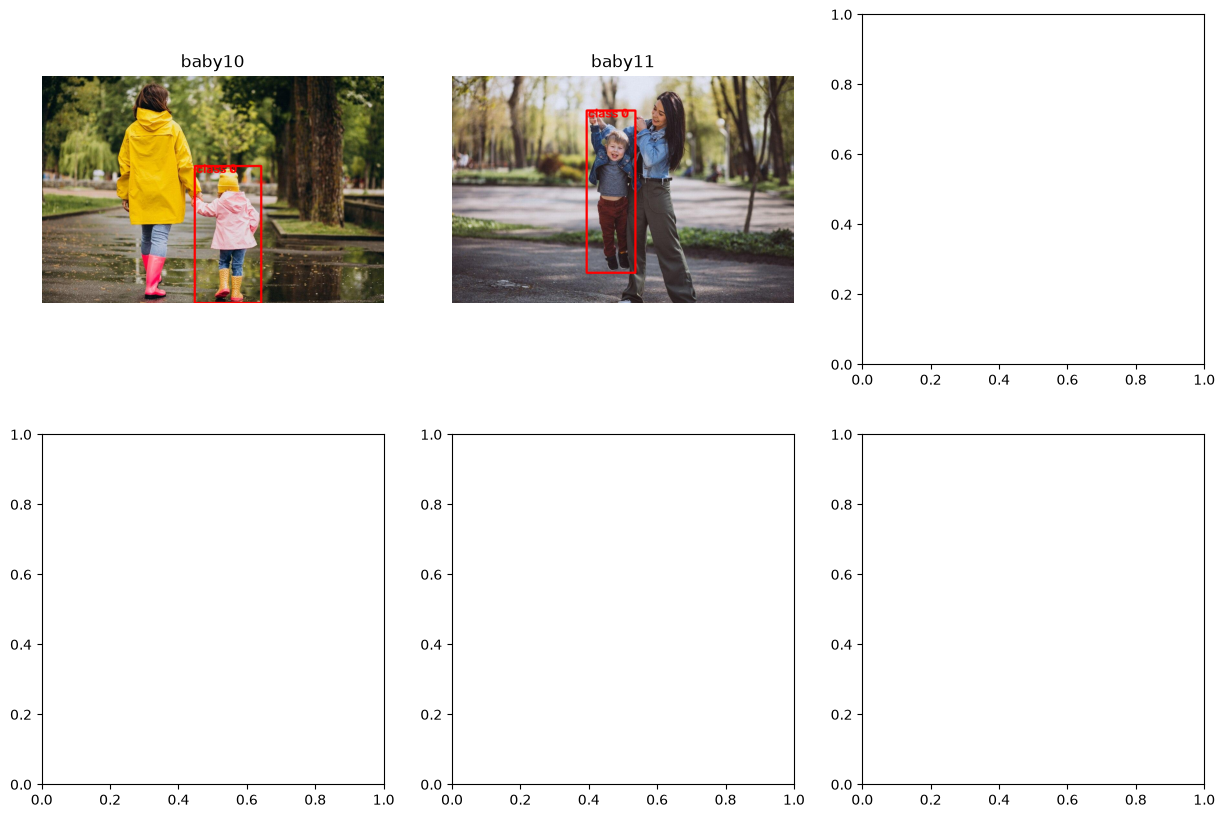

In [1]:
import cv2, random
import matplotlib.pyplot as plt
from pathlib import Path

root = Path(r"C:\Users\LENOVO\do_an\dataset\train_and_validation\baby")
split = "train"
colors = {"0": (255, 0, 0), "1": (0, 200, 0), "2": (0, 0, 255), "3": (255, 165, 0), "4": (160, 0, 200)}  # RGB

def find_image(stem):
    for ext in (".jpg", ".jpeg", ".png", ".JPG", ".PNG", ".jfif", ".bmp"):
        p = root / split / "images" / (stem + ext)
        if p.exists():
            return p
    return None

def draw(stem):
    p = find_image(stem)
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for line in (root / split / "labels" / f"{stem}.txt").read_text().splitlines():
        if not line.strip():
            continue
        c, x, y, bw, bh = line.split()[:5]
        x, y, bw, bh = float(x) * w, float(y) * h, float(bw) * w, float(bh) * h
        x1, y1, x2, y2 = int(x - bw / 2), int(y - bh / 2), int(x + bw / 2), int(y + bh / 2)
        col = colors.get(c, (0, 0, 0))
        cv2.rectangle(img, (x1, y1), (x2, y2), col, max(2, w // 200))
        cv2.putText(img, f"class {c}", (x1 + 4, max(y1 + 22, 22)),
                    cv2.FONT_HERSHEY_SIMPLEX, max(0.6, w / 800), col, 2)
    return img

# Xem các file cụ thể trước (nhiều hộp đã in ra) rồi thêm vài file ngẫu nhiên
stems = ["baby10", "baby11", "baby1164"]
all_baby = [f.stem for f in (root / split / "labels").glob("baby*.txt")]
stems += random.sample(all_baby, 3)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, s in zip(axes.ravel(), stems):
    ax.imshow(draw(s))
    ax.set_title(s)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
from pathlib import Path
from collections import Counter
import shutil

root = Path(r"C:\Users\LENOVO\do_an\dataset\train_and_validation")
DRY_RUN = False   # kiểm tra số liệu rồi đổi thành False để ghi thật

# Sao lưu một lần
if not DRY_RUN:
    for split in ["train", "val"]:
        bak = root / split / "labels_backup_baby"
        if not bak.exists():
            shutil.copytree(root / split / "labels", bak)

for split in ["train", "val"]:
    n_box, n_removed, n_empty = 0, 0, 0
    for f in (root / split / "labels").glob("baby*.txt"):
        rows = [l.split() for l in f.read_text().splitlines() if l.strip()]
        new = []
        for r in rows:
            if r[0] in ("1", "4"):                 # em bé (4 = đã đổi từ lần chạy trước)
                new.append("4 " + " ".join(r[1:]))
            else:                                  # class 0: loại bỏ
                n_removed += 1
        n_box += len(new)
        if not new:
            n_empty += 1
        if not DRY_RUN:
            f.write_text("\n".join(new) + ("\n" if new else ""))
    print(f"[{split}] hộp baby: {n_box} | hộp class 0 bị loại: {n_removed} | file không còn hộp: {n_empty}")

# Xóa cache nhãn
if not DRY_RUN:
    for split in ["train", "val"]:
        c = root / split / "labels.cache"
        if c.exists():
            c.unlink()

# Thống kê toàn bộ
for split in ["train", "val"]:
    cnt = Counter()
    for f in (root / split / "labels").glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                cnt[line.split()[0]] += 1
    print(split, dict(sorted(cnt.items())))

[train] hộp baby: 9 | hộp class 0 bị loại: 154 | file không còn hộp: 92
[val] hộp baby: 3 | hộp class 0 bị loại: 37 | file không còn hộp: 26
train {'0': 162, '1': 68, '2': 271, '3': 81, '4': 9}
val {'0': 41, '1': 20, '2': 88, '3': 25, '4': 3}


In [5]:
from pathlib import Path
from collections import Counter, defaultdict

root = Path(r"C:\Users\LENOVO\do_an\dataset\train_and_validation")
hazard_prefix = ("baterry", "electrical_outlet", "knife", "scissor","baby")

def group_of(stem):
    s = stem.lower()
    return next((p for p in hazard_prefix if s.startswith(p)), "KHÁC (baby?)")

for split in ["train", "val"]:
    table, files = defaultdict(Counter), Counter()
    for f in (root / split / "labels").glob("*.txt"):
        g = group_of(f.stem)
        files[g] += 1
        for line in f.read_text().splitlines():
            if line.strip():
                table[g][line.split()[0]] += 1
    print(f"[{split}]")
    for g in files:
        print(f"  {g:18s} file: {files[g]:4d} | hộp theo class: {dict(sorted(table[g].items()))}")

[train]
  KHÁC (baby?)       file:  120 | hộp theo class: {'0': 235, '1': 24}
  baterry            file:  110 | hộp theo class: {'0': 162}
  electrical_outlet  file:   67 | hộp theo class: {'1': 68}
  knife              file:  193 | hộp theo class: {'2': 271}
  scissor            file:   60 | hộp theo class: {'3': 81}
[val]
  KHÁC (baby?)       file:   48 | hộp theo class: {'0': 68, '1': 15}
  baterry            file:   29 | hộp theo class: {'0': 41}
  electrical_outlet  file:   19 | hộp theo class: {'1': 20}
  knife              file:   58 | hộp theo class: {'2': 88}
  scissor            file:   17 | hộp theo class: {'3': 25}


In [7]:
from pathlib import Path
from collections import Counter
import shutil

root = Path(r"C:\Users\LENOVO\do_an\dataset\train_and_validation")
hazard_prefix = ("baterry", "battery", "electrical_outlet", "knife", "scissor")

KEEP = {"0", "1"}     # class nguồn nào là em bé. Giữ cả "4" bên dưới để chạy lại không sao
DRY_RUN = False       # kiểm tra số liệu rồi đổi thành False

def is_hazard(stem):
    return stem.lower().startswith(hazard_prefix)

if not DRY_RUN:
    for split in ["train", "val"]:
        bak = root / split / "labels_backup_babyB"
        if not bak.exists():
            shutil.copytree(root / split / "labels", bak)

for split in ["train", "val"]:
    n_files, n_keep, n_drop, n_empty = 0, 0, 0, 0
    for f in (root / split / "labels").glob("*.txt"):
        if is_hazard(f.stem):
            continue                                   # không đụng vào vật nguy hiểm
        n_files += 1
        rows = [l.split() for l in f.read_text().splitlines() if l.strip()]
        new = []
        for r in rows:
            if r[0] in KEEP or r[0] == "4":
                new.append("4 " + " ".join(r[1:]))
                n_keep += 1
            else:
                n_drop += 1
        if not new:
            n_empty += 1
        if not DRY_RUN:
            f.write_text("\n".join(new) + ("\n" if new else ""))
    print(f"[{split}] file baby: {n_files} | hộp baby: {n_keep} | hộp bị loại: {n_drop} | file hết hộp: {n_empty}")

if not DRY_RUN:
    for split in ["train", "val"]:
        c = root / split / "labels.cache"
        if c.exists():
            c.unlink()

for split in ["train", "val"]:
    cnt = Counter()
    for f in (root / split / "labels").glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                cnt[line.split()[0]] += 1
    print(split, dict(sorted(cnt.items())))

[train] file baby: 120 | hộp baby: 259 | hộp bị loại: 0 | file hết hộp: 0
[val] file baby: 48 | hộp baby: 83 | hộp bị loại: 0 | file hết hộp: 0
train {'0': 162, '1': 68, '2': 271, '3': 81, '4': 259}
val {'0': 41, '1': 20, '2': 88, '3': 25, '4': 83}


In [1]:
import random
import shutil
import sys
from pathlib import Path

src = Path(r"C:\Users\LENOVO\do_an\dataset\original\dao")
dst = Path(r"C:\Users\LENOVO\do_an\dataset\repair_dataset")

files = [p for p in src.iterdir() if p.is_file()]
random.shuffle(files)

n = len(files)
n_a = round(n * 0.7)
n_b = round(n * 0.2)

groups = {"A": files[:n_a], "B": files[n_a:n_a + n_b], "C": files[n_a + n_b:]}

for name, items in groups.items():
    out = dst / name
    out.mkdir(exist_ok=True)
    for f in items:
        shutil.copy2(f, out / f.name)  # đổi thành shutil.move nếu muốn di chuyển
